# LAB 06 — Attention Mechanism

## Chuẩn bị

Notebook dùng `attention_numpy.py` cho hàm attention lõi và dữ liệu IMDB ở `lab05`.


In [22]:
import random
import re
import sys
import time
from collections import Counter
from pathlib import Path

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Image
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path("lab06").resolve() if Path("lab06/attention_numpy.py").exists() else Path.cwd()
sys.path.insert(0, str(ROOT))
from attention_numpy import softmax, scaled_dot_product_attention

SEED = 42
LENGTH = 80
BATCH = 64
EPOCHS = 3
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
print("Thư mục lab:", ROOT)


Thư mục lab: /home/chester/Documents/HUS_NLP/lab06


## Attention bằng NumPy

Q so khớp với K để tạo score; softmax tạo trọng số; tổng có trọng số của V tạo context.


In [23]:
Q = np.eye(2)
K = np.eye(2)
V = np.array([[1., 2.], [3., 4.]])
scores, weights, context = scaled_dot_product_attention(Q, K, V)
print("Scores:\n", scores)
print("Weights:\n", weights)
print("Context:\n", context)
print("Softmax ổn định:", softmax([1000, 1001, 1002]))


Scores:
 [[0.70710678 0.        ]
 [0.         0.70710678]]
Weights:
 [[0.66976155 0.33023845]
 [0.33023845 0.66976155]]
Context:
 [[1.6604769 2.6604769]
 [2.3395231 3.3395231]]
Softmax ổn định: [0.09003057 0.24472847 0.66524096]


## Thí nghiệm 1 — Phân phối attention và thay query

Cùng một câu, query về cảm xúc và query về chủ đề sẽ cho phân phối khác nhau. Các vector ở ví dụ này được gán thủ công.


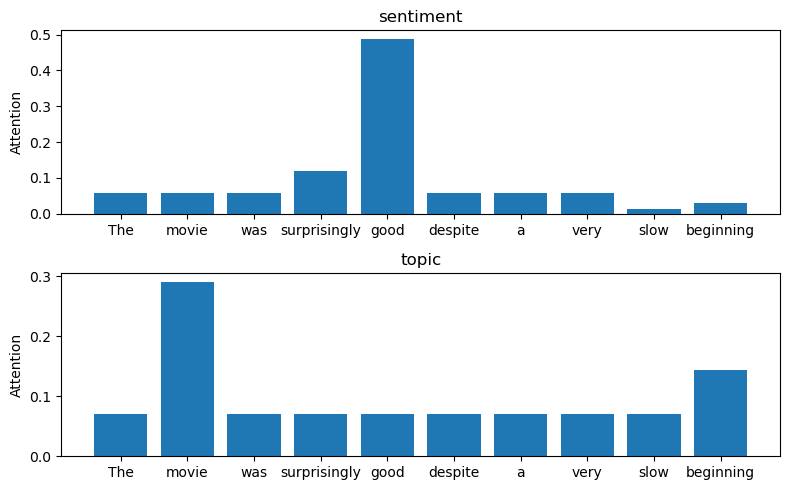

,Query,Token,Score,Attention
0,sentiment,The,0.000,0.058
1,sentiment,movie,0.000,0.058
2,sentiment,was,0.000,0.058
3,sentiment,surprisingly,0.707,0.119
4,sentiment,good,2.121,0.488
5,sentiment,despite,0.000,0.058
6,sentiment,a,0.000,0.058
7,sentiment,very,0.000,0.058
8,sentiment,slow,-1.414,0.014
9,sentiment,beginning,-0.707,0.029


In [24]:
def demo_attention():
    sentence = "The movie was surprisingly good despite a very slow beginning".split()
    # Hand-designed, two-dimensional keys: sentiment and movie-topic clues.
    keys = np.array([[0, 0], [0, 2], [0, 0], [1, 0], [3, 0],
                     [0, 0], [0, 0], [0, 0], [-2, 0], [-1, 1]], dtype=float)
    values = keys.copy()
    rows = []
    for name, query in [("sentiment", [1, 0]), ("topic", [0, 1])]:
        scores, weights, _ = scaled_dot_product_attention(np.array([query]), keys, values)
        for token, score, weight in zip(sentence, scores[0], weights[0]):
            rows.append(dict(Query=name, Token=token, Score=score, Attention=weight))
    fig, axes = plt.subplots(2, 1, figsize=(8, 5))
    for ax, name in zip(axes, ["sentiment", "topic"]):
        data = [r for r in rows if r["Query"] == name]
        ax.bar([r["Token"] for r in data], [r["Attention"] for r in data])
        ax.set_title(name)
        ax.set_ylabel("Attention")
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    return rows

distribution = pd.DataFrame(demo_attention())
display(distribution.round(3))


## Thí nghiệm 2 — Scaling và temperature

So sánh trọng số lớn nhất và entropy để xem phân phối tập trung hay phẳng hơn.


In [25]:
def temperature_experiment():
    scores = np.array([4., 2., 0.])
    rows = []
    for temp in [0.5, 1., 2.]:
        weights = softmax(scores / temp)
        rows.append(dict(Temperature=temp, Max_weight=weights.max(),
                         Entropy=-np.sum(weights * np.log(weights))))
    return rows


def scaling_experiment():
    scores = np.array([4., 2., 0.])
    rows = []
    for name, used in [("unscaled", scores), ("scaled", scores / np.sqrt(4))]:
        weights = softmax(used)
        rows.append(dict(Method=name, Max_weight=weights.max(),
                         Entropy=-np.sum(weights * np.log(weights))))
    return rows

display(pd.DataFrame(scaling_experiment()).round(3))
display(pd.DataFrame(temperature_experiment()).round(3))


,Method,Max_weight,Entropy
0,unscaled,0.867,0.441
1,scaled,0.665,0.832


,Temperature,Max_weight,Entropy
0,0.5,0.982,0.093
1,1.0,0.867,0.441
2,2.0,0.665,0.832


## Thí nghiệm 3 — Self-attention và heatmap

Mỗi hàng là token đang chú ý, mỗi cột là token được chú ý. Các ô có cùng diện tích; màu đậm hơn biểu thị trọng số lớn hơn. Vector minh họa được gán thủ công, không phải biểu diễn đã học.


,Token,Top_token,Weight
0,cat,cat,0.286
1,adopted,cat,0.286
2,sleeping,cat,0.286


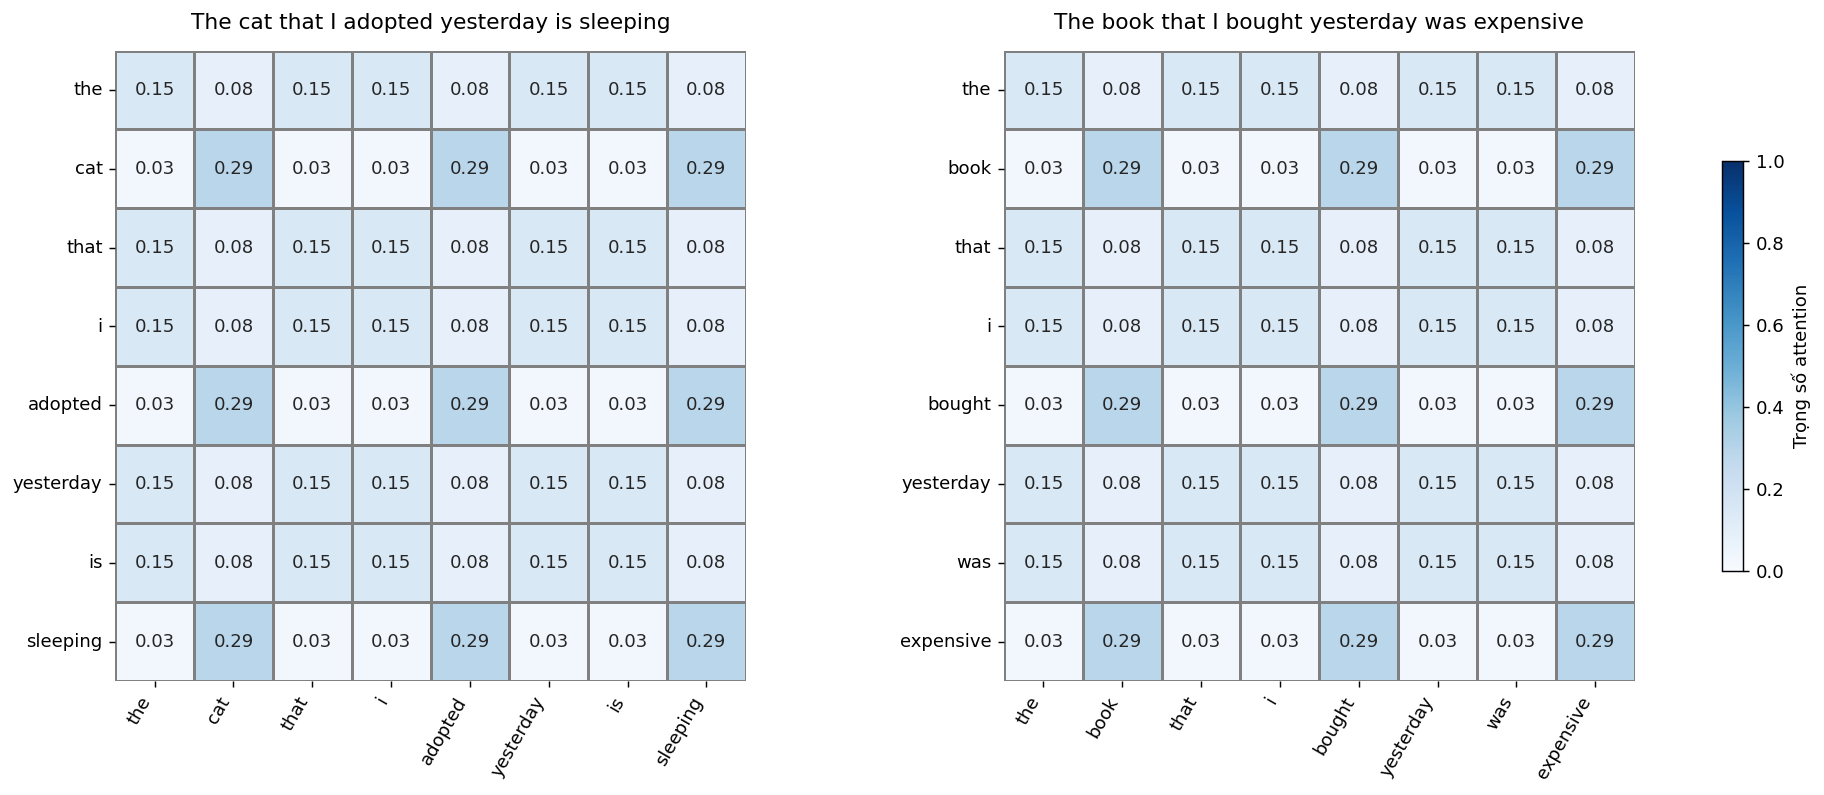

In [26]:
def tokens(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", str(text).lower())


def self_attention_demo():
    examples = [
        "The cat that I adopted yesterday is sleeping",
        "The book that I bought yesterday was expensive"
    ]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(15, 6),
        constrained_layout=True
    )

    summaries = []

    semantic = {
        "cat": [2, 0, 0],
        "adopted": [2, 0, 0],
        "sleeping": [2, 0, 0],
        "book": [0, 2, 0],
        "bought": [0, 2, 0],
        "expensive": [0, 2, 0]
    }

    for ax, sentence in zip(axes, examples):
        words = tokens(sentence)

        X = np.array(
            [semantic.get(w, [0, 0, 1]) for w in words],
            dtype=float
        )

        Wq = np.eye(3)
        Wk = np.eye(3)
        Wv = np.eye(3)

        Q, K, V = X @ Wq, X @ Wk, X @ Wv

        _, A, _ = scaled_dot_product_attention(Q, K, V)

        # Seaborn Heatmap
        sns.heatmap(
            A,
            ax=ax,
            xticklabels=words,
            yticklabels=words,
            cmap="Blues",
            vmin=0,
            vmax=1,
            linewidths=0.8,
            linecolor="gray",
            square=True,
            cbar=False,
            annot=True,
            fmt=".2f"
        )

        ax.set_title(sentence, fontsize=12, pad=12)
        ax.tick_params(axis="x", rotation=60)
        ax.tick_params(axis="y", rotation=0)

        for label in ax.get_xticklabels():
            label.set_ha("right")

        for word in ["cat", "adopted", "sleeping"]:
            if word in words:
                i = words.index(word)
                j = int(np.argmax(A[i]))

                summaries.append({
                    "Token": word,
                    "Top_token": words[j],
                    "Weight": A[i, j]
                })

    # Colorbar chung cho cả hai heatmap
    sm = plt.cm.ScalarMappable(
        cmap="Blues",
        norm=plt.Normalize(vmin=0, vmax=1)
    )
    sm.set_array([])

    fig.colorbar(
        sm,
        ax=axes,
        shrink=0.65,
        label="Trọng số attention"
    )

    fig.savefig(
        ROOT / "attention_heatmap.png",
        dpi=130,
        bbox_inches="tight"
    )

    plt.close(fig)

    return summaries


display(pd.DataFrame(self_attention_demo()).round(3))
display(Image(filename=str(ROOT / "attention_heatmap.png")))

## Thí nghiệm 4 — LSTM và Attention trên IMDB

Dùng cùng một tập con, tối đa 80 token và 3 epoch. LSTM lấy hidden state cuối của token thật; Attention dùng ma trận tương tác giữa token và gộp các context.


In [27]:
def prepare_data():
    frame = pd.read_csv(ROOT.parent / "lab05" / "IMDB_Dataset.csv")
    frame["label"] = (frame.sentiment == "positive").astype(int)
    train_pool, test_pool = train_test_split(frame, test_size=0.2, stratify=frame.label, random_state=SEED)
    train, _ = train_test_split(train_pool, train_size=3000, stratify=train_pool.label, random_state=SEED)
    val, _ = train_test_split(train_pool.drop(train.index), train_size=500,
                              stratify=train_pool.drop(train.index).label, random_state=SEED)
    test, _ = train_test_split(test_pool, train_size=500, stratify=test_pool.label, random_state=SEED)
    count = Counter(w for text in train.review for w in tokens(text))
    vocab = {"<PAD>": 0, "<UNK>": 1}
    vocab.update((word, i + 2) for i, (word, _) in enumerate(count.most_common(9998)))
    return train, val, test, vocab


def encode(text, vocab):
    ids = [vocab.get(w, 1) for w in tokens(text)[:LENGTH]] or [1]
    return ids + [0] * (LENGTH - len(ids)), len(ids)


def loader(frame, vocab, shuffle=False):
    pairs = [encode(t, vocab) for t in frame.review]
    x = torch.tensor([p[0] for p in pairs], dtype=torch.long)
    lengths = torch.tensor([p[1] for p in pairs], dtype=torch.long)
    y = torch.tensor(frame.label.to_numpy(), dtype=torch.float32)
    return DataLoader(TensorDataset(x, lengths, y), batch_size=BATCH, shuffle=shuffle)


class SentimentModel(nn.Module):
    def __init__(self, kind, vocab_size, dim=32):
        super().__init__()
        self.kind = kind
        self.embedding = nn.Embedding(vocab_size, dim, padding_idx=0)
        if kind == "LSTM":
            self.encoder = nn.LSTM(dim, dim, batch_first=True)
        else:
            self.position = nn.Embedding(LENGTH, dim)
            self.q = nn.Linear(dim, dim, bias=False)
            self.k = nn.Linear(dim, dim, bias=False)
            self.v = nn.Linear(dim, dim, bias=False)
        self.classifier = nn.Linear(dim, 1)

    def forward(self, ids, lengths, return_weights=False):
        x = self.embedding(ids)
        if self.kind == "LSTM":
            packed = nn.utils.rnn.pack_padded_sequence(
                x, lengths.cpu(), batch_first=True, enforce_sorted=False
            )
            _, (h, _) = self.encoder(packed)
            context = h[-1]
            weights = None
        else:
            positions = torch.arange(ids.shape[1], device=ids.device)
            x = x + self.position(positions)
            q, k, v = self.q(x), self.k(x), self.v(x)
            scores = q @ k.transpose(1, 2) / (q.shape[-1] ** 0.5)
            mask = ids.ne(0)
            scores = scores.masked_fill(~mask[:, None, :], -1e9)
            weights = torch.softmax(scores, dim=-1)
            context_per_token = weights @ v
            context = (context_per_token * mask[:, :, None]).sum(dim=1) / lengths[:, None]
        logits = self.classifier(context).squeeze(-1)
        return (logits, weights) if return_weights else logits


def evaluate(model, data):
    model.eval()
    all_y, all_p = [], []
    with torch.no_grad():
        for x, lengths, y in data:
            all_y.extend(y.numpy())
            all_p.extend(torch.sigmoid(model(x, lengths)).numpy())
    y, p = np.array(all_y), np.array(all_p)
    return y, p


def train_model(kind, train, val, test, vocab):
    torch.manual_seed(SEED)
    model = SentimentModel(kind, len(vocab))
    optimizer = torch.optim.Adam(model.parameters(), lr=0.002)
    loss_fn = nn.BCEWithLogitsLoss()
    train_data = loader(train, vocab, shuffle=True)
    val_data = loader(val, vocab)
    start = time.perf_counter()
    best_loss = float("inf")
    best_state = None
    for epoch in range(EPOCHS):
        model.train()
        for x, lengths, y in train_data:
            optimizer.zero_grad()
            loss = loss_fn(model(x, lengths), y)
            loss.backward()
            optimizer.step()
        vy, vp = evaluate(model, val_data)
        val_loss = float(loss_fn(torch.tensor(np.log(np.clip(vp, 1e-7, 1-1e-7) /
                                            (1-np.clip(vp, 1e-7, 1-1e-7)))),
                                  torch.tensor(vy)).item())
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(kind, "epoch", epoch + 1, "val loss", round(val_loss, 4), flush=True)
    seconds = time.perf_counter() - start
    model.load_state_dict(best_state)
    y, p = evaluate(model, loader(test, vocab))
    row = dict(Model=kind, Accuracy=accuracy_score(y, p >= 0.5), F1=f1_score(y, p >= 0.5),
               Training_time_s=seconds, Parameters=sum(t.numel() for t in model.parameters()),
               Train_size=len(train), Test_size=len(test), Max_length=LENGTH)
    return model, row, y, p

train, val, test, vocab = prepare_data()
print("Train / validation / test:", len(train), len(val), len(test))
print("Vocabulary:", len(vocab))


Train / validation / test: 3000 500 500
Vocabulary: 10000


LSTM epoch 1 val loss 0.6913
LSTM epoch 2 val loss 0.6898
LSTM epoch 3 val loss 0.689
Attention epoch 1 val loss 0.6843
Attention epoch 2 val loss 0.6315
Attention epoch 3 val loss 0.6095


,Model,Accuracy,F1,Training_time_s,Parameters,Train_size,Test_size,Max_length
0,LSTM,0.530,0.591,11.833,328481,3000,500,80
1,Attention,0.676,0.727,2.143,325665,3000,500,80


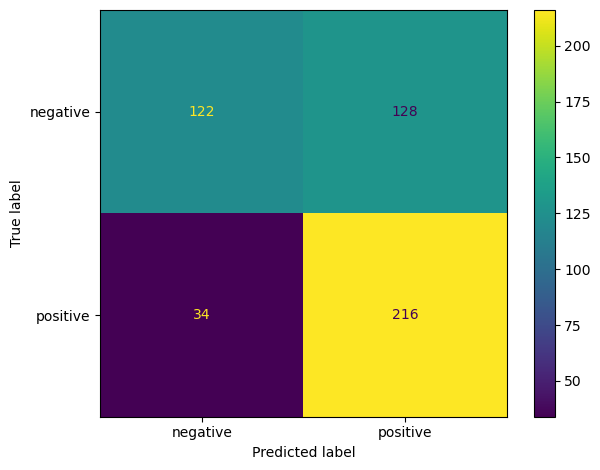

In [28]:
lstm, lstm_row, _, _ = train_model("LSTM", train, val, test, vocab)
model, attention_row, y, p = train_model("Attention", train, val, test, vocab)
results = pd.DataFrame([lstm_row, attention_row])
results.to_csv(ROOT / "results.csv", index=False)
display(results.round(3))
ConfusionMatrixDisplay.from_predictions(y, p >= 0.5, display_labels=["negative", "positive"])
plt.tight_layout()
plt.savefig(ROOT / "confusion_matrix.png", dpi=130)
plt.show()


## Ứng dụng — Ba câu sentiment

Quan sát prediction, xác suất positive và attention trung bình trên các vị trí query thật.


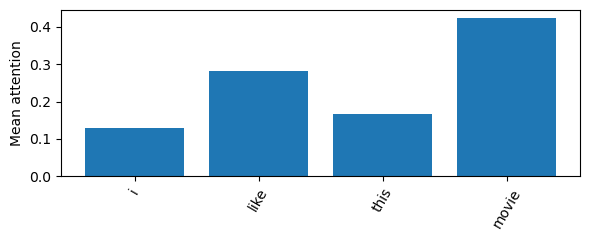

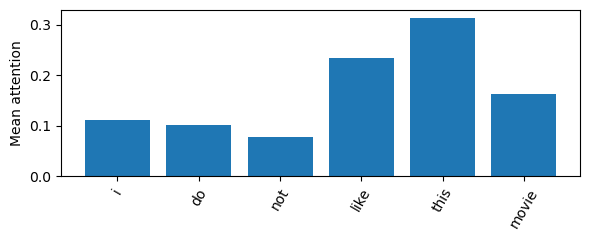

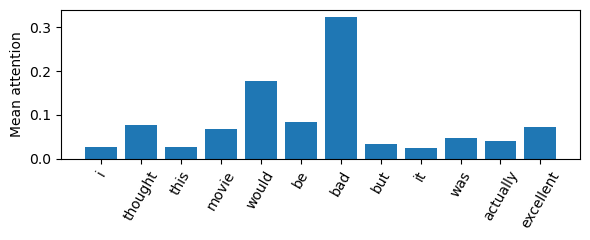

,Case,Text,True_label,Predicted,Positive_probability,Top_attention_token
0,like,I like this movie.,1,1,0.540,movie
1,not_like,I do not like this movie.,0,0,0.408,this
2,contrast,"I thought this movie would be bad, but it was ...",1,0,0.015,bad


In [29]:
def plot_prediction(model, text, vocab):
    ids, length = encode(text, vocab)
    with torch.no_grad():
        logit, weights = model(torch.tensor([ids]), torch.tensor([length]), True)
        probability = torch.sigmoid(logit).item()
    importance = weights[0, :length, :length].mean(dim=0).numpy()
    words = tokens(text)[:LENGTH]
    fig, ax = plt.subplots(figsize=(max(6, 0.5 * length), 2.5))
    ax.bar(words, importance)
    ax.tick_params(axis="x", rotation=60)
    ax.set_ylabel("Mean attention")
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    return probability, words[int(np.argmax(importance))]

examples = [
    ("like", "I like this movie.", 1),
    ("not_like", "I do not like this movie.", 0),
    ("contrast", "I thought this movie would be bad, but it was actually excellent.", 1),
]
application = []
for name, text, label in examples:
    prob, top = plot_prediction(model, text, vocab)
    application.append(dict(Case=name, Text=text, True_label=label,
                            Predicted=int(prob >= 0.5), Positive_probability=prob,
                            Top_attention_token=top))
application = pd.DataFrame(application)
display(application.round(3))


## Phân tích 3 mẫu đúng và 3 mẫu sai

Các ví dụ lấy từ test set. Attention là phân phối trọng số; cần kiểm tra thêm trước khi kết luận nguyên nhân dự đoán.


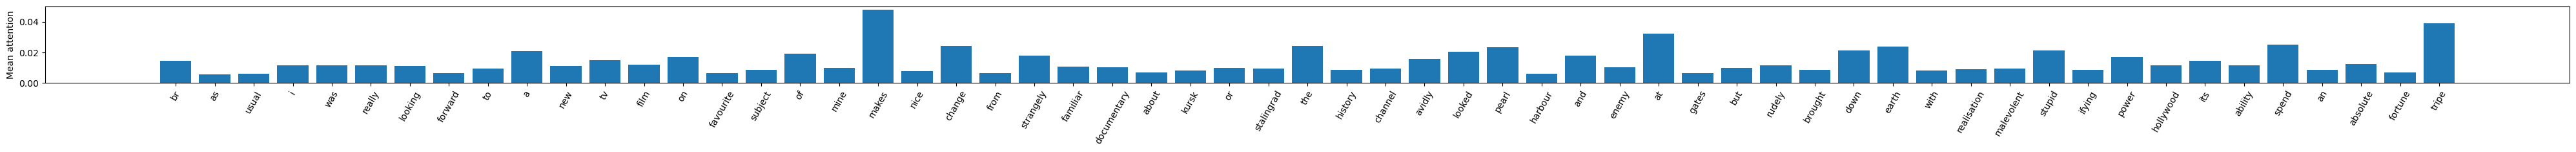

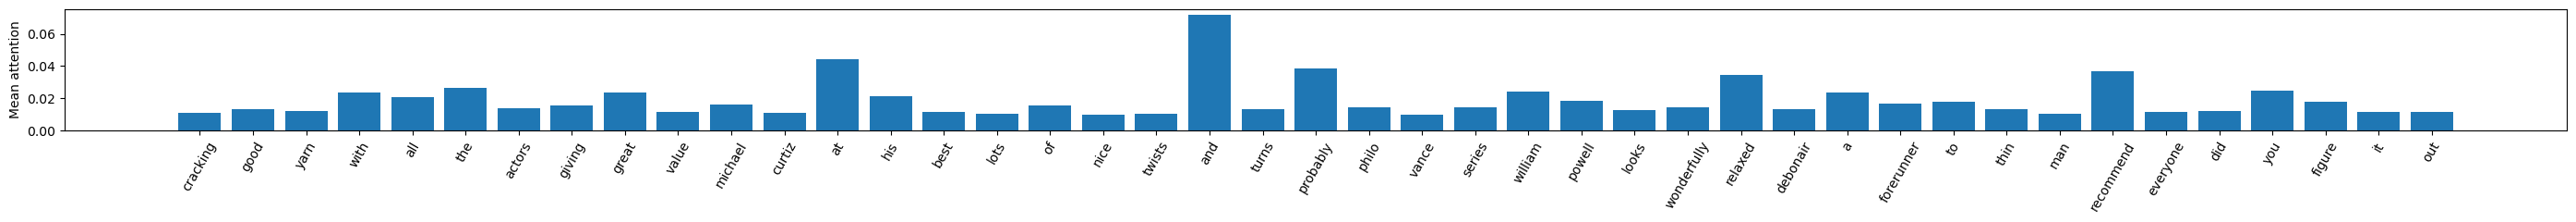

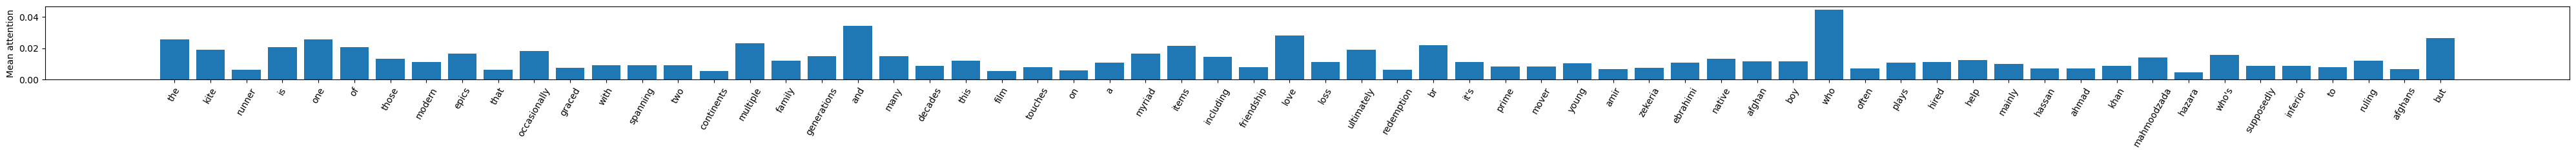

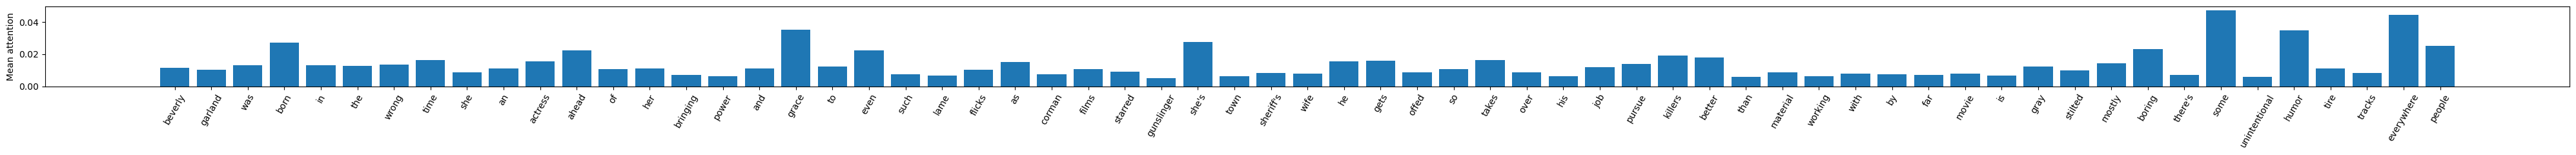

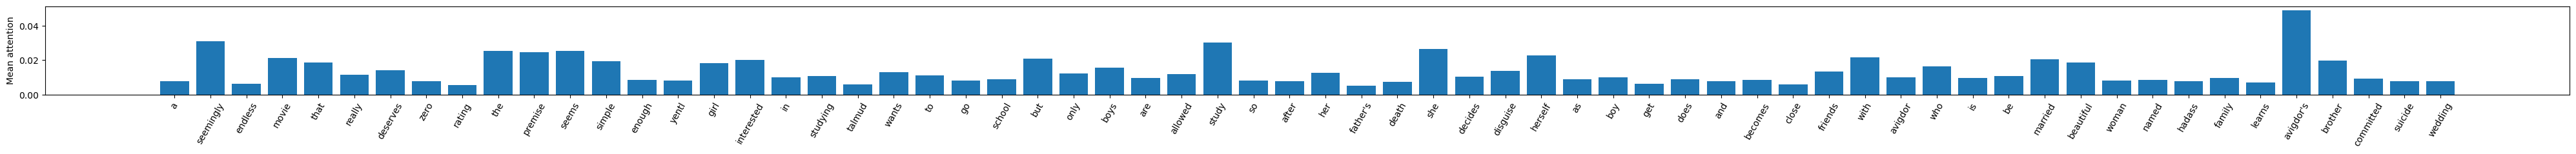

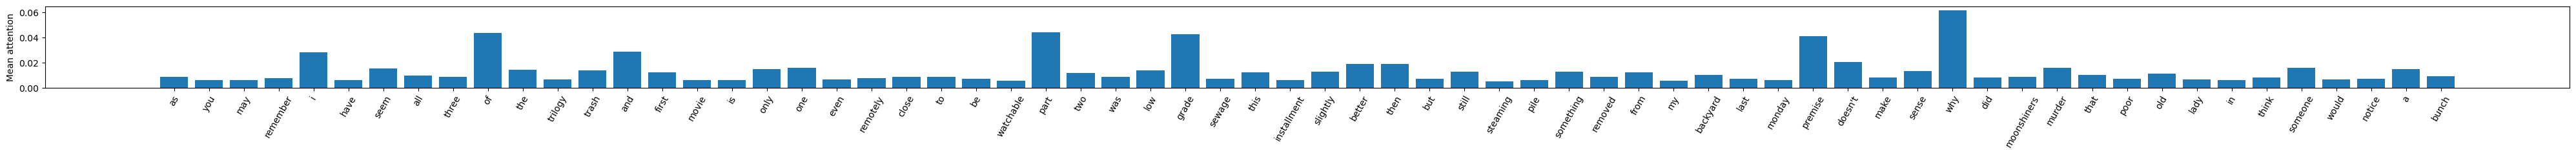

,Index,Correct,True_label,Predicted,Positive_probability,Top_attention_token,Truncated,Text
0,0,True,0,0,0.460,makes,True,"<br /><br />As usual, I was really looking for..."
1,1,True,1,1,0.915,and,False,Cracking good yarn with all the actors giving ...
2,3,True,1,1,0.764,who,True,THE KITE RUNNER is one of those modern epics t...
3,2,False,0,1,0.759,some,True,Beverly garland was born in the wrong time. Sh...
4,4,False,0,1,0.696,avigdor's,True,A seemingly endless movie that really deserves...
5,11,False,0,1,0.673,why,True,As you may remember I have seem all three of t...


In [30]:
sample = test.reset_index(drop=True)
selection = []
for correct in [True, False]:
    indices = np.flatnonzero((y == (p >= 0.5)) == correct)[:3]
    for i in indices:
        text = sample.loc[i, "review"]
        _, top = plot_prediction(model, text, vocab)
        selection.append(dict(Index=int(i), Correct=correct, True_label=int(y[i]),
                              Predicted=int(p[i] >= 0.5), Positive_probability=float(p[i]),
                              Top_attention_token=top, Truncated=len(tokens(text)) > LENGTH,
                              Text=text[:250]))
selection = pd.DataFrame(selection)
display(selection.round(3))


## Độ dài chuỗi và giới hạn

Full self-attention có ma trận N × N: chiều dài gấp đôi làm số phần tử tăng khoảng bốn lần. Trọng số attention cho thấy mô hình phân phối chú ý như thế nào, chưa chứng minh mô hình suy luận hoặc hiểu ngữ pháp.


In [31]:
lengths = [10, 100, 500, 1000]
display(pd.DataFrame({"Sequence_length": lengths,
                      "Attention_matrix": [f"{t} × {t}" for t in lengths],
                      "Elements": [t * t for t in lengths]}))


,Sequence_length,Attention_matrix,Elements
0,10,10 × 10,100
1,100,100 × 100,10000
2,500,500 × 500,250000
3,1000,1000 × 1000,1000000
